# SLM Classification-Head Training for Sinhala Hate/Offensive Speech

Train only the sequence-classification head of small language models while keeping the base model frozen in BF16/FP16. The benchmark trains on one condition and evaluates on all selected conditions, matching the clean/noisy robustness setup used in the `llama8b` and `sinllama` notebooks.


## 1. Install dependencies

Run once, then restart the runtime if any packages were newly installed.


In [9]:
%pip install -q -U "transformers>=4.45" "accelerate>=1.0" "datasets>=3.0" pandas scikit-learn matplotlib seaborn huggingface_hub

Note: you may need to restart the kernel to use updated packages.


## 2. Configuration

Set `TRAIN_DATASETS` to one condition for a quick run, or all three for the full benchmark. The default model is ungated so the notebook can run without special Hugging Face approval; switch to a gated Llama key only after your HF account has accepted the model licence.


In [ ]:
from pathlib import Path
import dataclasses
import gc
import json
import os
import time

import numpy as np
import pandas as pd
import torch

SEED = 42
NUM_LABELS = 2
LABEL_NAME = {0: "NOT", 1: "OFF"}
LABEL2ID = {v: k for k, v in LABEL_NAME.items()}

# Set to a concrete data directory if auto-detection cannot find this repo's data folder.
DATA_ROOT = None
OUTPUT_ROOT = Path("benchmark_results/classification_head_only")

# Train-one-condition, test-all-conditions setup.
# "clean", "codemix", "transliteration"
TRAIN_DATASETS = ["clean", "codemix", "transliteration"]
TEST_DATASETS = ["clean", "codemix", "transliteration"]
TRAIN_SUBSET = None  # e.g. 200 for a smoke test

# Dataset variants used by this template.
CODEMIX_SEVERITY = "heavy"
TRANSLITERATION_SEVERITY = "heavy"

# Llama repositories are gated on Hugging Face. Use the ungated Qwen default
# unless your HF account has been approved for the selected Llama model.



MODELS = {
  
    "qwen_4b": "Qwen/Qwen3-4B",
    "qwen_8b": "Qwen/Qwen3-8B",
    "llama_3b_gated": "meta-llama/Llama-3.2-3B",
    "llama_8b_gated": "meta-llama/Llama-3.1-8B",
    "sinllama_gated": "polyglots/SinLlama_v01",
}

# Change ACTIVE_MODELS assigned to you and change TRAIN_DATASETS array if you want to change train
# datasets. You can also change TEST_DATASETS array if you want to change test datasets. 

# Naveen - Sinllama
# Sansala - Qwen/Qwen3-4B,
# Dulakshi - Qwen/Qwen3-8B,
# Janodi - meta-llama/Llama-3.2-3B,meta-llama/Llama-3.1-8B

ACTIVE_MODELS = ["qwen_4b"]

EPOCHS = 3.0
LEARNING_RATE = 2e-4
TRAIN_BATCH_SIZE = 8
EVAL_BATCH_SIZE = 8
GRADIENT_ACCUMULATION_STEPS = 4
MAX_LENGTH = 128
WEIGHT_DECAY = 0.01
VALIDATION_FRACTION = 0.10
LOGGING_STEPS = 10
MODEL_LOAD_MODE = "bf16/fp16"
OPTIMIZER = "adamw_torch"

np.random.seed(SEED)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("torch", torch.__version__, "| CUDA", torch.cuda.is_available())
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(i)
        print(f"cuda:{i} {props.name}, {props.total_memory / 2**30:.1f} GiB")

torch 2.13.0+cu130 | CUDA True
cuda:0 NVIDIA GeForce RTX 4070 Ti SUPER, 15.6 GiB


## 3. Authenticate and locate data

No token is stored in this notebook. Set `HF_TOKEN` as an environment/Kaggle secret, or authenticate interactively if needed.

In [11]:
from huggingface_hub import login

hf_token = os.environ.get("HF_TOKEN")
if hf_token:
    login(token=hf_token, add_to_git_credential=False)
    print("Authenticated from HF_TOKEN.")
else:
    print("HF_TOKEN is not set. Ungated models will still work; gated models require an approved token.")

REQUIRED = [
    Path("sold/train.jsonl"),
    Path("sold/test.jsonl"),
    Path(f"outputs/train/codemix_{CODEMIX_SEVERITY}.jsonl"),
    Path(f"outputs/test/codemix_{CODEMIX_SEVERITY}.jsonl"),
    Path(f"outputs/train/transliteration_{TRANSLITERATION_SEVERITY}.jsonl"),
    Path(f"outputs/test/transliteration_{TRANSLITERATION_SEVERITY}.jsonl"),
]

def is_data_root(path):
    path = Path(path)
    return all((path / rel).is_file() for rel in REQUIRED)

def find_data_root(explicit=None):
    if explicit is not None:
        explicit = Path(explicit)
        if not is_data_root(explicit):
            raise FileNotFoundError(f"Invalid DATA_ROOT: {explicit.resolve()}")
        return explicit
    cwd = Path.cwd().resolve()
    for parent in (cwd, *cwd.parents):
        for candidate in (parent / "data", parent):
            if is_data_root(candidate):
                return candidate
    kaggle = Path("/kaggle/input")
    if kaggle.exists():
        for train_file in kaggle.glob("**/sold/train.jsonl"):
            candidate = train_file.parent.parent
            if is_data_root(candidate):
                return candidate
    raise FileNotFoundError("Could not locate the dataset. Set DATA_ROOT explicitly.")

DATA_ROOT = find_data_root(DATA_ROOT)
FILES = {
    "clean_train": DATA_ROOT / "sold/train.jsonl",
    "clean_test": DATA_ROOT / "sold/test.jsonl",
    "codemix_train": DATA_ROOT / f"outputs/train/codemix_{CODEMIX_SEVERITY}.jsonl",
    "codemix_test": DATA_ROOT / f"outputs/test/codemix_{CODEMIX_SEVERITY}.jsonl",
    "transliteration_train": DATA_ROOT / f"outputs/train/transliteration_{TRANSLITERATION_SEVERITY}.jsonl",
    "transliteration_test": DATA_ROOT / f"outputs/test/transliteration_{TRANSLITERATION_SEVERITY}.jsonl",
}
print("DATA_ROOT =", DATA_ROOT.resolve())


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Authenticated from HF_TOKEN.
DATA_ROOT = /home/cse_g6/project/Sinhala-Noisy-Hatespeech-Data/data


## 4. Load and validate datasets

Clean SOLD files use `post_id` and `text`; generated noisy files use `source_id` and `noisy_text`. This cell canonicalizes both schemas to `id`, `text`, and `label`.

In [12]:
def read_jsonl(path):
    records = []
    with Path(path).open(encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            line = line.strip()
            if not line:
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as exc:
                raise ValueError(f"Invalid JSON in {path}, line {line_number}: {exc}") from exc
    if not records:
        raise ValueError(f"Dataset is empty: {path}")
    return pd.DataFrame(records)

def normalize_label_series(labels):
    mapping = {
        "0": 0, "1": 1,
        "NOT": 0, "OFF": 1,
        "not": 0, "off": 1,
        "negative": 0, "positive": 1,
        "not-offensive": 0, "offensive": 1,
        "non-hate": 0, "hate": 1,
    }
    normalized = labels.astype(str).str.strip().map(mapping)
    if normalized.isna().any():
        bad = sorted(labels[normalized.isna()].astype(str).unique().tolist())
        raise ValueError(f"Unmapped labels: {bad}")
    return normalized.astype(int)

def canonicalize(df, condition, split):
    id_candidates = ("post_id", "source_id", "id", "sentence_id", "orig_id")
    text_candidates = ("text", "noisy_text", "transliterated", "transliteration", "romanized")
    id_col = next((col for col in id_candidates if col in df.columns), None)
    text_col = next((col for col in text_candidates if col in df.columns), None)
    if id_col is None or text_col is None or "label" not in df.columns:
        raise KeyError(f"{condition}_{split}: unsupported columns {df.columns.tolist()}")
    out = df[[id_col, text_col, "label"]].rename(columns={id_col: "id", text_col: "text"}).copy()
    out["id"] = out["id"].astype(str)
    out["text"] = out["text"].astype(str)
    out["label"] = normalize_label_series(out["label"])
    if out["id"].duplicated().any():
        raise ValueError(f"{condition}_{split}: duplicate IDs found")
    if out["text"].str.strip().eq("").any():
        raise ValueError(f"{condition}_{split}: empty text found")
    out["condition"] = condition
    out["split"] = split
    return out

frames = {}
for condition in ("clean", "codemix", "transliteration"):
    for split in ("train", "test"):
        key = f"{condition}_{split}"
        frames[key] = canonicalize(read_jsonl(FILES[key]), condition, split)
        counts = frames[key]["label"].value_counts().sort_index().to_dict()
        print(f"{key:24s} n={len(frames[key]):5d} labels={counts}")

for split in ("train", "test"):
    reference = frames[f"clean_{split}"].set_index("id")
    for condition in ("codemix", "transliteration"):
        candidate = frames[f"{condition}_{split}"].set_index("id")
        assert set(candidate.index) == set(reference.index), f"{condition}_{split}: ID mismatch"
        candidate = candidate.loc[reference.index]
        assert np.array_equal(candidate["label"], reference["label"]), f"{condition}_{split}: label mismatch"

display(pd.DataFrame({
    "clean": frames["clean_test"]["text"].head(3),
    "codemix": frames["codemix_test"]["text"].head(3),
    "transliteration": frames["transliteration_test"]["text"].head(3),
    "label": frames["clean_test"]["label"].head(3).map(LABEL_NAME),
}))

clean_train              n= 7500 labels={0: 4324, 1: 3176}
clean_test               n= 2500 labels={0: 1485, 1: 1015}
codemix_train            n= 7500 labels={0: 4324, 1: 3176}
codemix_test             n= 2500 labels={0: 1485, 1: 1015}
transliteration_train    n= 7500 labels={0: 4324, 1: 3176}
transliteration_test     n= 2500 labels={0: 1485, 1: 1015}


,clean,codemix,transliteration,label
0,තේ නෙවෙයි තෝ බීලා ඉන්නෙ ගිනි වතුර,තේ නෙවෙයි තෝ බීලා ඉන්නෙ ගිනි water,th newey tho bila inne gini… wathura,NOT
1,@USER තුනක් ඕනේ නෑ එකක් ගැහුවනම් ඇති ලංකාවට ආප...,@USER තුනක් ඕනේ නෑ එකක් ගැහුවනම් ඇති ලංකාවට ආප...,@USER thunakk one ne ekak gahuwanam athi lanka...,NOT
2,"@USER , @USER @USER ටහුඩු ඒකි තනියම ජීවත් වෙ...","@USER , @USER @USER ටහුඩු ඒකි alone live වෙන...","@USER , @USER @USER tahudu eki thaniyama jiw...",NOT


## 5. Tokenizer and Head-Only Model

The base model is frozen in BF16/FP16. Only common sequence-classification head parameters such as `score`, `classifier`, or `classification_head` are trainable. Do not use pure 4-bit quantization for this baseline; `Trainer` only supports fine-tuning quantized models when trainable adapters are attached.


In [13]:
from datasets import ClassLabel, Dataset
from huggingface_hub.errors import GatedRepoError
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    set_seed,
)

COMPUTE_DTYPE = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else torch.float16

def explain_gated_model_error(model_id, exc):
    raise RuntimeError(
        f"Cannot access gated Hugging Face model '{model_id}'. "
        "Either request access on the model page and set HF_TOKEN to an approved token, "
        "or choose an ungated key such as 'qwen_3b' in ACTIVE_MODELS."
    ) from exc


def build_tokenizer(model_id):
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True, use_fast=True)
    except (GatedRepoError, OSError) as exc:
        if "gated repo" in str(exc).lower() or "restricted" in str(exc).lower():
            explain_gated_model_error(model_id, exc)
        raise
    tokenizer.padding_side = "right"
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    return tokenizer

def make_dataset(frame, tokenizer):
    dataset = Dataset.from_pandas(frame[["id", "text", "label"]], preserve_index=False)
    dataset = dataset.cast_column("label", ClassLabel(names=["NOT", "OFF"]))
    return dataset.map(
        lambda batch: tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH),
        batched=True,
        remove_columns=["text"],
    )

def set_trainable_classification_head(model):
    for parameter in model.parameters():
        parameter.requires_grad = False
    trainable_names = []
    head_markers = ("score", "classifier", "classification_head")
    for name, parameter in model.named_parameters():
        if any(marker in name for marker in head_markers):
            parameter.requires_grad = True
            trainable_names.append(name)
            print("TRAINABLE:", name, tuple(parameter.shape))
    if not trainable_names:
        print("No head was found automatically. Candidate parameter names:")
        for name, parameter in model.named_parameters():
            print(name, tuple(parameter.shape))
        raise RuntimeError("Modify head_markers in set_trainable_classification_head for this model.")
    total = sum(parameter.numel() for parameter in model.parameters())
    trainable = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    print(f"Total parameters:     {total:,}")
    print(f"Trainable parameters: {trainable:,} ({100 * trainable / total:.6f}%)")

def build_model(model_id, tokenizer):
    model_kwargs = dict(
        num_labels=NUM_LABELS,
        id2label=LABEL_NAME,
        label2id=LABEL2ID,
        pad_token_id=tokenizer.pad_token_id,
        device_map="auto",
        torch_dtype=COMPUTE_DTYPE,
        trust_remote_code=True,
        low_cpu_mem_usage=True,
    )
    try:
        model = AutoModelForSequenceClassification.from_pretrained(model_id, **model_kwargs)
    except (GatedRepoError, OSError) as exc:
        if "gated repo" in str(exc).lower() or "restricted" in str(exc).lower():
            explain_gated_model_error(model_id, exc)
        raise
    if model.config.pad_token_id is None:
        model.config.pad_token_id = tokenizer.pad_token_id
    model.config.use_cache = False
    set_trainable_classification_head(model)
    return model


## 6. Metrics and trainer

Macro-F1 is the checkpoint-selection metric. The weighted loss helps with SOLD label imbalance.

In [14]:
import inspect

import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    precision_recall_fscore_support,
)
from transformers import Trainer, TrainingArguments

def metric_values(labels, predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, labels=[0, 1], zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, predictions),
        "balanced_accuracy": balanced_accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro", zero_division=0),
        "not_precision": precision[0], "not_recall": recall[0], "not_f1": f1[0],
        "off_precision": precision[1], "off_recall": recall[1], "off_f1": f1[1],
    }

def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    return metric_values(labels, np.argmax(logits, axis=-1))

def trainer_tokenizer_kwargs(tokenizer):
    parameters = inspect.signature(Trainer.__init__).parameters
    if "processing_class" in parameters:
        return {"processing_class": tokenizer}
    if "tokenizer" in parameters:
        return {"tokenizer": tokenizer}
    return {}

class WeightedTrainer(Trainer):
    def __init__(self, class_weights=None, **kwargs):
        super().__init__(**kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        weights = self.class_weights.to(outputs.logits.device, outputs.logits.dtype)
        loss = nn.CrossEntropyLoss(weight=weights)(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def make_class_weights(frame):
    counts = frame["label"].value_counts().sort_index().reindex([0, 1], fill_value=0).to_numpy()
    if (counts == 0).any():
        raise ValueError(f"Both classes must appear in the training split. Counts: {counts.tolist()}")
    weights = counts.sum() / (NUM_LABELS * counts)
    return torch.tensor(weights, dtype=torch.float32)

def training_arguments(output_dir):
    kwargs = dict(
        output_dir=str(output_dir / "checkpoints"),
        seed=SEED,
        num_train_epochs=EPOCHS,
        per_device_train_batch_size=TRAIN_BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        eval_accumulation_steps=8,
        learning_rate=LEARNING_RATE,
        lr_scheduler_type="cosine",
        warmup_ratio=0.06,
        weight_decay=WEIGHT_DECAY,
        max_grad_norm=0.3,
        fp16=COMPUTE_DTYPE == torch.float16,
        bf16=COMPUTE_DTYPE == torch.bfloat16,
        optim=OPTIMIZER,
        logging_steps=LOGGING_STEPS,
        eval_strategy="epoch",
        evaluation_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        report_to="none",
        dataloader_num_workers=2,
        dataloader_pin_memory=False,
        group_by_length=True,
        label_names=["labels"],
    )
    valid = {field.name for field in dataclasses.fields(TrainingArguments)}
    return TrainingArguments(**{key: value for key, value in kwargs.items() if key in valid})

## 7. Run one model/training-condition experiment

In [15]:
def evaluate_dataset(trainer, dataset, frame, model_name, model_id, train_condition, test_condition, output_dir):
    prediction_output = trainer.predict(dataset)
    predictions = np.argmax(prediction_output.predictions, axis=-1)
    labels = prediction_output.label_ids
    metrics = metric_values(labels, predictions)
    report = classification_report(
        labels,
        predictions,
        labels=[0, 1],
        target_names=[LABEL_NAME[0], LABEL_NAME[1]],
        zero_division=0,
        output_dict=True,
    )
    result = {
        "model": model_name,
        "model_id": model_id,
        "train_dataset": train_condition,
        "test_dataset": test_condition,
        "num_test_samples": len(dataset),
        **metrics,
    }
    predictions_frame = pd.DataFrame({
        "id": frame["id"].to_numpy(),
        "model": model_name,
        "train_dataset": train_condition,
        "test_dataset": test_condition,
        "label": labels,
        "prediction": predictions,
        "text": frame["text"].to_numpy(),
    })
    with (output_dir / f"{test_condition}_classification_report.json").open("w", encoding="utf-8") as handle:
        json.dump(report, handle, indent=2)
    return result, predictions_frame

def run_experiment(model_name, train_condition):
    model_id = MODELS[model_name]
    if model_id.startswith("YOUR_"):
        raise ValueError(f"Replace placeholder model ID for {model_name}: {model_id}")

    print("\n" + "=" * 80)
    print(f"MODEL: {model_name} | TRAIN: {train_condition}")
    print("=" * 80)

    set_seed(SEED)
    output_dir = OUTPUT_ROOT / model_name / f"train_{train_condition}_seed{SEED}"
    output_dir.mkdir(parents=True, exist_ok=True)

    train_frame = frames[f"{train_condition}_train"].copy()
    if TRAIN_SUBSET is not None:
        train_frame = train_frame.sample(n=min(TRAIN_SUBSET, len(train_frame)), random_state=SEED).reset_index(drop=True)

    tokenizer = build_tokenizer(model_id)
    full_train = make_dataset(train_frame, tokenizer)
    split = full_train.train_test_split(
        test_size=VALIDATION_FRACTION,
        seed=SEED,
        stratify_by_column="label",
    )
    train_ds, validation_ds = split["train"], split["test"]

    model = build_model(model_id, tokenizer)
    tokenizer_kwargs = trainer_tokenizer_kwargs(tokenizer)
    trainer = WeightedTrainer(
        model=model,
        args=training_arguments(output_dir),
        train_dataset=train_ds,
        eval_dataset=validation_ds,
        data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
        compute_metrics=compute_metrics,
        class_weights=make_class_weights(train_frame),
        **tokenizer_kwargs,
    )

    started = time.time()
    trainer.train()
    trainer.save_model(output_dir / "model")
    tokenizer.save_pretrained(output_dir / "model")

    result_rows = []
    prediction_frames = []
    for test_condition in TEST_DATASETS:
        test_frame = frames[f"{test_condition}_test"].copy()
        test_ds = make_dataset(test_frame, tokenizer)
        result, predictions = evaluate_dataset(
            trainer, test_ds, test_frame, model_name, model_id, train_condition, test_condition, output_dir
        )
        result["num_train_samples"] = len(train_ds)
        result["num_validation_samples"] = len(validation_ds)
        result["elapsed_hours"] = (time.time() - started) / 3600
        result_rows.append(result)
        prediction_frames.append(predictions)
        print(f"{test_condition:16s} macro_f1={result['macro_f1']:.4f} accuracy={result['accuracy']:.4f}")

    results = pd.DataFrame(result_rows)
    predictions = pd.concat(prediction_frames, ignore_index=True)
    results.to_csv(output_dir / "metrics.csv", index=False)
    predictions.to_json(output_dir / "predictions.jsonl", orient="records", lines=True, force_ascii=False)
    with (output_dir / "run_summary.json").open("w", encoding="utf-8") as handle:
        json.dump({
            "model": model_name,
            "model_id": model_id,
            "train_condition": train_condition,
            "test_conditions": TEST_DATASETS,
            "seed": SEED,
            "epochs": EPOCHS,
            "learning_rate": LEARNING_RATE,
            "max_length": MAX_LENGTH,
            "model_load_mode": MODEL_LOAD_MODE,
            "fine_tuning_method": "classification_head_only",
        }, handle, indent=2)

    del trainer, model, tokenizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return results, predictions

## 8. Run configured benchmark

A full `5 models x 3 train datasets x 3 test datasets` run creates 45 evaluations. Start with one model and `TRAIN_SUBSET=200` for a smoke test.

In [16]:
all_results = []
all_predictions = []
started = time.time()

for model_name in ACTIVE_MODELS:
    for train_condition in TRAIN_DATASETS:
        results, predictions = run_experiment(model_name, train_condition)
        all_results.append(results)
        all_predictions.append(predictions)

        partial_results = pd.concat(all_results, ignore_index=True)
        partial_results.to_csv(OUTPUT_ROOT / "benchmark_summary_partial.csv", index=False)

results = pd.concat(all_results, ignore_index=True)
predictions = pd.concat(all_predictions, ignore_index=True)
results.to_csv(OUTPUT_ROOT / "benchmark_summary.csv", index=False)
predictions.to_json(OUTPUT_ROOT / "all_predictions.jsonl", orient="records", lines=True, force_ascii=False)

matrix = results.pivot_table(index=["model", "train_dataset"], columns="test_dataset", values="macro_f1")
matrix.to_csv(OUTPUT_ROOT / "macro_f1_matrix.csv")
display(results.round(4))
display(matrix.round(4))
print(f"Finished in {(time.time() - started) / 3600:.2f} hours")
print("Artifacts:", OUTPUT_ROOT.resolve())


MODEL: qwen_3b | TRAIN: clean


Loading weights: 100%|██████████| 434/434 [00:00<00:00, 563.26it/s]
[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-3B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


TRAINABLE: score.weight (2, 2048)
Total parameters:     3,085,942,784
Trainable parameters: 4,096 (0.000133%)


Epoch,Training Loss,Validation Loss,Accuracy,Balanced Accuracy,Macro F1,Not Precision,Not Recall,Not F1,Off Precision,Off Recall,Off F1
1,2.971983,0.747259,0.556000,0.551930,0.550495,0.623441,0.578704,0.600240,0.478510,0.525157,0.500750


Map: 100%|██████████| 2500/2500 [00:00<00:00, 29240.42 examples/s]


clean            macro_f1=0.5470 accuracy=0.5580


... (3 outputs left out)

transliteration  macro_f1=0.4951 accuracy=0.5736


,model,model_id,train_dataset,test_dataset,num_test_samples,accuracy,balanced_accuracy,macro_f1,not_precision,not_recall,not_f1,off_precision,off_recall,off_f1,num_train_samples,num_validation_samples,elapsed_hours
0,qwen_3b,Qwen/Qwen2.5-3B,clean,clean,2500,0.5580,0.5481,0.5470,0.6353,0.6007,0.6175,0.4589,0.4956,0.4766,6750,750,0.0830
1,qwen_3b,Qwen/Qwen2.5-3B,clean,codemix,2500,0.5380,0.5243,0.5240,0.6143,0.5973,0.6057,0.4337,0.4512,0.4423,6750,750,0.1027
2,qwen_3b,Qwen/Qwen2.5-3B,clean,transliteration,2500,0.5736,0.5178,0.4951,0.6047,0.8148,0.6942,0.4489,0.2207,0.2959,6750,750,0.1099


,test_dataset,clean,codemix,transliteration
model,train_dataset,,,
qwen_3b,clean,0.547,0.524,0.4951


Finished in 0.11 hours
Artifacts: /home/cse_g6/project/Sinhala-Noisy-Hatespeech-Data/templates/benchmark_results/classification_head_only


## 9. Plot macro-F1 matrix

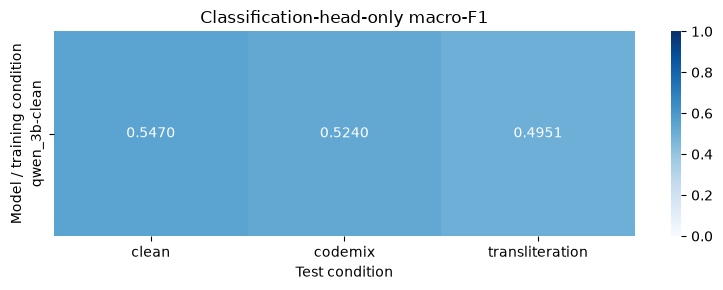

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_matrix = matrix.reindex(columns=TEST_DATASETS)
plt.figure(figsize=(8, max(3, 0.45 * len(plot_matrix))))
sns.heatmap(plot_matrix, annot=True, fmt=".4f", cmap="Blues", vmin=0, vmax=1)
plt.title("Classification-head-only macro-F1")
plt.xlabel("Test condition")
plt.ylabel("Model / training condition")
plt.tight_layout()
plt.savefig(OUTPUT_ROOT / "macro_f1_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

## Reporting checklist

Report model ID/revision, trainable head parameter names, quantization, training condition and size, validation policy, seed, epochs, learning rate, effective batch size, truncation length, and clean/codemix/transliteration metrics. Keep smoke-test results separate from full-data results.